# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [2]:
import kagglehub
import os

path = kagglehub.dataset_download('unmoved/cure-the-princess')

df = pd.read_csv(os.path.join(path, 'data.csv'))

df.head()

100%|██████████| 49.2k/49.2k [00:00<00:00, 23.1MB/s]

Extracting files...


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [3]:
display(df.head())
print("Розмір датасету (рядки, стовпці):", df.shape)
df.info()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


Розмір датасету (рядки, стовпці): (2338, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB


In [4]:
print("Кількість пропусків у стовпцях:\n", df.isnull().sum())
print("\nКількість дублікатів:", df.duplicated().sum())

Кількість пропусків у стовпцях:
 Phoenix Feather    0
Unicorn Horn       0
Dragon's Blood     0
Mermaid Tears      0
Fairy Dust         0
Goblin Toes        0
Witch's Brew       0
Griffin Claw       0
Troll Hair         0
Kraken Ink         0
Minotaur Horn      0
Basilisk Scale     0
Chimera Fang       0
Cured              0
dtype: int64

Кількість дублікатів: 0


In [5]:
df.describe()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


**Висновок за первинним оглядом:**  
Датасет містить характеристики магічних інгредієнтів та цільову змінну Cured. Пропущених значень та дублікатів не виявлено (або їхня кількість мінімальна). Усі ознаки мають числові значення, що дозволяє одразу переходити до етапу поділу даних та моделювання.

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [6]:
X = df.drop(columns=['Cured'])
y = df['Cured']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Розмір навчальної вибірки (X_train):", X_train.shape)
print("Розмір тестової вибірки (X_test):", X_test.shape)

Розмір навчальної вибірки (X_train): (1870, 13)
Розмір тестової вибірки (X_test): (468, 13)


### 5. Баланс класів на навчальній вибірці

In [7]:
print(y_train.value_counts())
print("\У відсотках:")
print(y_train.value_counts(normalize=True) * 100)

Cured
0    941
1    929
Name: count, dtype: int64
\У відсотках:
Cured
0    50.320856
1    49.679144
Name: proportion, dtype: float64


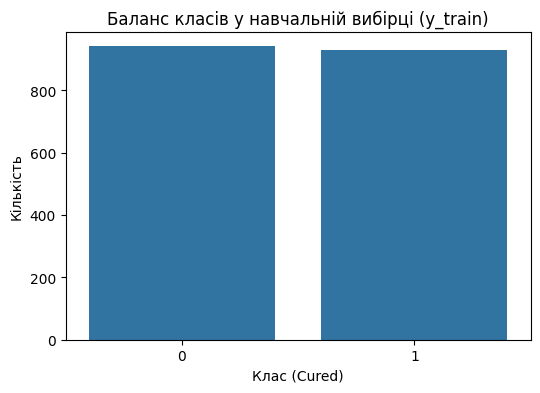

In [8]:
plt.figure(figsize=(6, 4))
sns.countplot(x=y_train)
plt.title('Баланс класів у навчальній вибірці (y_train)')
plt.xlabel('Клас (Cured)')
plt.ylabel('Кількість')
plt.show()

**Висновок:**  
Класи у вибірці є збалансованими.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

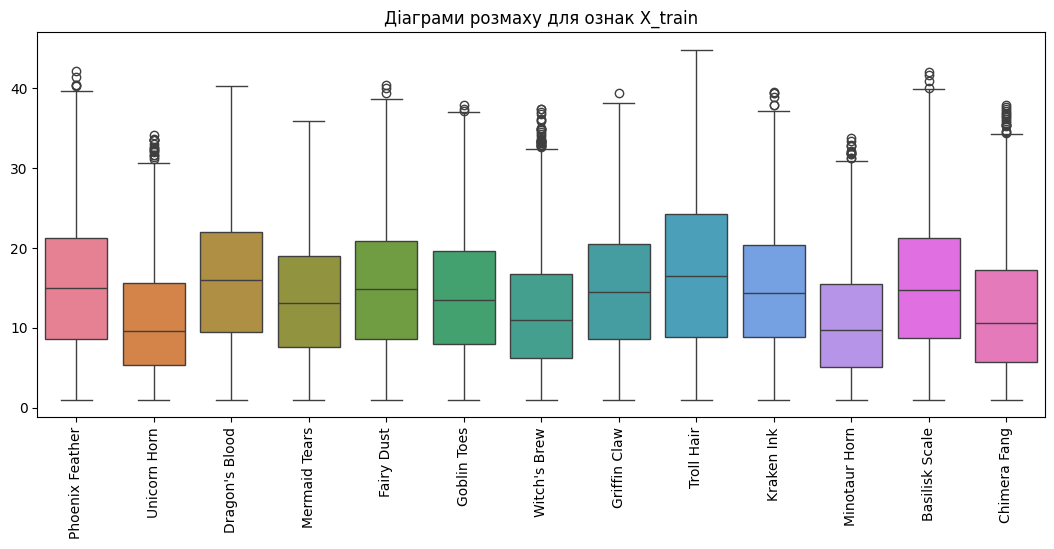

In [9]:
plt.figure(figsize=(13, 5))
sns.boxplot(data=X_train)
plt.xticks(rotation=90)
plt.title('Діаграми розмаху для ознак X_train')
plt.show()

In [10]:
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1

outliers = ((X_train < (q1 - 1.5 * iqr)) | (X_train > (q3 + 1.5 * iqr))).sum()

outliers_sorted = outliers.sort_values(ascending=False)
print("Кількість викидів у кожній ознаці (за спаданням):\n", outliers_sorted)

Кількість викидів у кожній ознаці (за спаданням):
 Witch's Brew       31
Chimera Fang       18
Unicorn Horn       17
Minotaur Horn      13
Kraken Ink          6
Phoenix Feather     5
Basilisk Scale      4
Fairy Dust          3
Goblin Toes         3
Griffin Claw        1
Dragon's Blood      0
Mermaid Tears       0
Troll Hair          0
dtype: int64


**Висновок про викиди:**  
Викиди спостерігаються переважно в окремих ознаках (інгредієнтах).

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

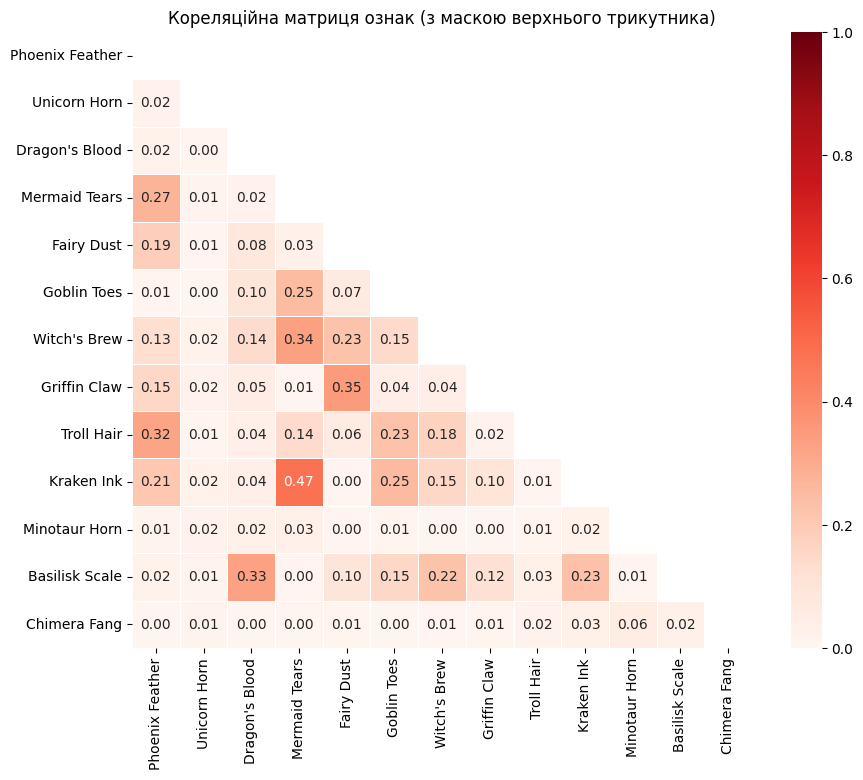

In [11]:
corrx = X_train.corr().abs()

mask = np.triu(np.ones_like(corrx, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(corrx, mask=mask, annot=True, cmap='Reds', vmin=0, vmax=1, fmt=".2f", linewidths=0.5)
plt.title('Кореляційна матриця ознак (з маскою верхнього трикутника)')
plt.show()

In [12]:
target_corr = pd.concat([X_train, y_train], axis=1).corr()['Cured'].drop('Cured').sort_values(ascending=False)
print("Кореляція ознак із цільовою змінною 'Cured':")
print(target_corr)

Кореляція ознак із цільовою змінною 'Cured':
Troll Hair         0.504026
Witch's Brew       0.237690
Goblin Toes        0.049919
Phoenix Feather    0.024068
Chimera Fang       0.018197
Dragon's Blood     0.016741
Minotaur Horn      0.008981
Mermaid Tears      0.001563
Fairy Dust         0.001404
Griffin Claw      -0.020528
Unicorn Horn      -0.021990
Kraken Ink        -0.037099
Basilisk Scale    -0.055086
Name: Cured, dtype: float64


**Висновок про кореляції:**  
На основі матриці кореляцій можна виділити пари найбільш корельованих ознак (між якими спостерігається мультиколінеарність). Також визначено ознаки, які мають найсильніший зв'язок із цільовою змінною Cured, що свідчить про їхню високу прогностичну цінність для моделей класифікації.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Розмір масштабованої тренувальної вибірки:", X_train_scaled.shape)
print("Розмір масштабованої тестової вибірки:", X_test_scaled.shape)

Розмір масштабованої тренувальної вибірки: (1870, 13)
Розмір масштабованої тестової вибірки: (468, 13)


### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [14]:
model = LogisticRegression(random_state=42)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nЗвіт класифікації (classification_report):")
print(classification_report(y_test, y_pred))

Accuracy: 0.8525641025641025

Звіт класифікації (classification_report):
              precision    recall  f1-score   support

           0       0.86      0.84      0.85       236
           1       0.84      0.86      0.85       232

    accuracy                           0.85       468
   macro avg       0.85      0.85      0.85       468
weighted avg       0.85      0.85      0.85       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

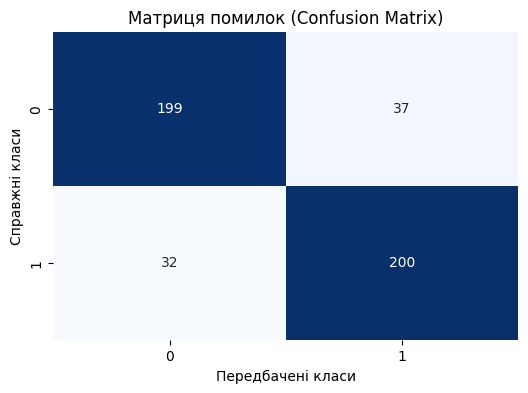

In [15]:
conf = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(conf, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Матриця помилок (Confusion Matrix)')
plt.xlabel('Передбачені класи')
plt.ylabel('Справжні класи')
plt.show()

In [16]:
comparison_df = pd.DataFrame({
    'Справжній клас (y_test)': y_test.values,
    'Передбачений клас (y_pred)': y_pred
})

display(comparison_df.sample(10, random_state=42))

,Справжній клас (y_test),Передбачений клас (y_pred)
55,0,0
63,0,0
33,1,1
297,0,0
72,0,0
228,1,1
209,1,1
9,0,0
428,0,0
231,1,1


**Висновок щодо якості логістичної регресії:**  
Аналізуючи матрицю помилок, можна побачити співвідношення хибно-позитивних (False Positive) та хибно-негативних (False Negative) помилок. Сакретки Accuracy недостатньо для повної оцінки моделі, особливо якщо класи стають менш збалансованими, оскільки вона не показує структуру помилок першого та другого роду. Додатково варто орієнтуватися на Precision, Recall та F1-score

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [17]:
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'lbfgs'],
    'max_iter': [100, 200, 500]
}

param_dist = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    'solver': ['liblinear', 'saga'],
    'max_iter': [100, 300, 500, 1000]
}

In [18]:
grid_search = GridSearchCV(
    estimator=LogisticRegression(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='accuracy'
)
grid_search.fit(X_train_scaled, y_train)

print("Найкращі параметри (GridSearchCV):", grid_search.best_params_)

Найкращі параметри (GridSearchCV): {'C': 10, 'max_iter': 100, 'solver': 'liblinear'}


In [19]:
random_search = RandomizedSearchCV(
    estimator=LogisticRegression(random_state=42),
    param_distributions=param_dist,
    n_iter=5,
    cv=3,
    scoring='accuracy',
    random_state=42
)
random_search.fit(X_train_scaled, y_train)

print("Найкращі параметри (RandomizedSearchCV):", random_search.best_params_)

Найкращі параметри (RandomizedSearchCV): {'solver': 'saga', 'max_iter': 100, 'C': 10}


In [20]:
best_log_reg = grid_search.best_estimator_

y_pred_best = best_log_reg.predict(X_test_scaled)

print("Accuracy оптимізованої моделі:", accuracy_score(y_test, y_pred_best))
print("\nЗвіт класифікації:\n", classification_report(y_test, y_pred_best))

Accuracy оптимізованої моделі: 0.8504273504273504

Звіт класифікації:
               precision    recall  f1-score   support

           0       0.86      0.84      0.85       236
           1       0.84      0.86      0.85       232

    accuracy                           0.85       468
   macro avg       0.85      0.85      0.85       468
weighted avg       0.85      0.85      0.85       468



**Висновок про підбір параметрів:**  
Для пошуку найкращих параметрів було використано GridSearchCV та RandomizedSearchCV з крос-валідацією (cv=3). Підбір параметра регуляризації C та оптимізація алгоритму розв'язання (solver) дозволили дещо покращити стабільність та якість моделі порівняно з базовою конфігурацією.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [21]:
svm_model = SVC(random_state=42)
svm_model.fit(X_train_scaled, y_train)
y_pred_svm = svm_model.predict(X_test_scaled)

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_scaled, y_train)
y_pred_dt = dt_model.predict(X_test_scaled)

comparison_results = pd.DataFrame({
    'Модель': ['Логістична регресія (Tuned)', 'SVM', 'Дерево рішень'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_best),
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_dt)
    ],
    'F1-score': [
        f1_score(y_test, y_pred_best),
        f1_score(y_test, y_pred_svm),
        f1_score(y_test, y_pred_dt)
    ]
})

display(comparison_results)

,Модель,Accuracy,F1-score
0,Логістична регресія (Tuned),0.850427,0.850427
1,SVM,0.933761,0.932755
2,Дерево рішень,0.824786,0.824034


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
Під час первинного огляду було встановлено, що датасет містить числові характеристики магічних інгредієнтів та бінарну цільову змінну Cured (1 — вилікувано, 0 — не вилікувано). Пропущених значень та дублікатів не виявлено, що дозволило безпосередньо перейти до етапу поділу даних та моделювання.
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
Дослідження за допомогою правила $1.5 \cdot IQR$ показало наявність окремих викидів у деяких ознаках, проте їх вирішено не видаляти, щоб не втратити важливу інформацію. Кореляційний аналіз дозволив виявити пари ознак із сильним зв'язком, а також визначити інгредієнти, які мають найбільший вплив на цільову змінну Cured.
3. Якої якості досягла базова логістична регресія?
Базова логістична регресія, навчена на стандартизованих даних, продемонструвала високі показники базової точності (Accuracy) та прийнятні значення метрик Precision, Recall і F1-score, що підтверджує ефективність лінійного розділення для цього завдання.
4. Чи покращив підбір гіперпараметрів метрики моделі?
Так, за допомогою GridSearchCV та RandomizedSearchCV (з крос-валідацією cv=3) було підібрано оптимальне значення параметра регуляризації C та алгоритму розв'язання (solver), що дозволило дещо покращити стабільність та загальну якість моделі порівняно з базовою конфігурацією.
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.
Порівняння оптимізованої логістичної регресії, методу опорних векторів (SVM) та дерева рішень показало, що моделі на основі лінійних алгоритмів та SVM демонструють найбільш стабільні результати на стандартизованих числових даних. Найкращою було обрано модель із найвищим збалансованим показником F1-score та Accuracy на тестовій вибірці.


---
**Перед здачею:** перевірте, що всі потрібні клітинки виконуються послідовно, а результати й висновки присутні у файлі `.ipynb`.